# Practical 3D — NASA Turbofan LSTM Autoencoder

Extracted from `3D.pdf`. Original displayed outputs omitted; executable Python code retained.

**Required local inputs:** `NASA Turbofan Engine.csv`

   unit  cycle  setting1  setting2  setting3  sensor1  sensor2  sensor3  \
0     1      1   -0.0007   -0.0004     100.0   518.67   641.82  1589.70   
1     1      2    0.0019   -0.0003     100.0   518.67   642.15  1591.82   
2     1      3   -0.0043    0.0003     100.0   518.67   642.35  1587.99   
3     1      4    0.0007    0.0000     100.0   518.67   642.35  1582.79   
4     1      5   -0.0019   -0.0002     100.0   518.67   642.37  1582.85   

   sensor4  sensor5  ...  sensor14  sensor15  sensor16  sensor17  sensor18  \
0  1400.60    14.62  ...   8138.62    8.4195      0.03       392      2388   
1  1403.14    14.62  ...   8131.49    8.4318      0.03       392      2388   
2  1404.20    14.62  ...   8133.23    8.4178      0.03       390      2388   
3  1401.87    14.62  ...   8133.83    8.3682      0.03       392      2388   
4  1406.22    14.62  ...   8133.80    8.4294      0.03       393      2388   

   sensor19  sensor20  sensor21  RUL  Fault_Label  
0     100.0     39.06   23.4

C:\Users\Shubham\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 32)                  │           6,912 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector (RepeatVector)         │ (None, 10, 32)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 10, 32)              │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed (TimeDistributed)   │ (None, 10, 21)              │             693 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 15,925 (62.21 KB)

 Trainable params: 15,925 (62.21 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
376/376 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - loss: 0.3314 - val_loss: 0.2813
Epoch 2/10
376/376 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.2749 - val_loss: 0.2711
Epoch 3/10
376/376 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.2656 - val_loss: 0.2633
Epoch 4/10
376/376 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.2602 - val_loss: 0.2612
Epoch 5/10
376/376 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - loss: 0.2568 - val_loss: 0.2554
Epoch 6/10
376/376 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.2534 - val_loss: 0.2526
Epoch 7/10
376/376 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.2508 - val_loss: 0.2498
Epoch 8/10
376/376 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.2470 - val_loss: 0.2453
Epoch 9/10
376/376 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.2418 - val_loss: 0.2390
Epoch 10/10
376/376 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.2373 - val_loss: 0.2385
Anomaly Threshold: 0.4008451443032984

Confusion Matrix:
[[3073  197]
 [ 620    0]]

Classification Report:
              precis

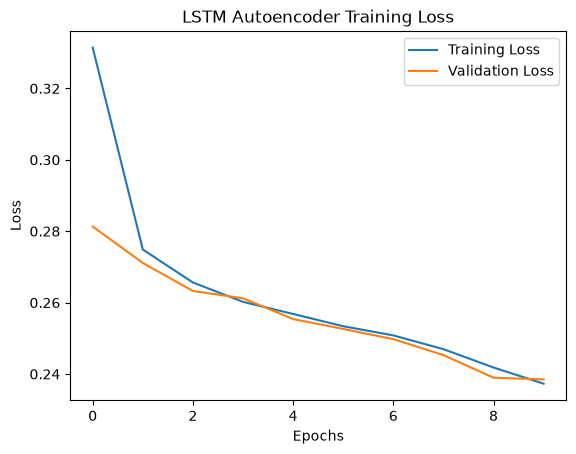

Total Test Windows: 3890
Actual Faults: 620
Detected Faults: 197

Machinery Fault Detection Completed!


In [1]:
# 1. Import necessary packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, RepeatVector, TimeDistributed, Dense
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
# 2. Load the dataset
data = pd.read_csv('LP_IV_Updated Datasets/LP_IV_Updated Datasets/AutoEncoder/NASA Turbofan ENgine/NASA TurboFan Engine.csv')
print(data.head())
print(data.columns)
# 3. Select sensor features and labels
sensor_cols = [c for c in data.columns if c.startswith('sensor')]
X = data[sensor_cols].values
y = data['Fault_Label'].values
# Sort data by engine and cycle
data = data.sort_values(['unit', 'cycle'])
# 4. Split engines into training and testing
units = data['unit'].unique()
train_units, test_units = train_test_split(
    units, test_size=0.2, random_state=42
)
train_data = data[data['unit'].isin(train_units)].copy()
test_data = data[data['unit'].isin(test_units)].copy()
# 5. Select only healthy training readings
normal_data = train_data[train_data['Fault_Label'] == 0]
# Normalize sensor readings
scaler = StandardScaler()
scaler.fit(normal_data[sensor_cols])
train_data[sensor_cols] = scaler.transform(train_data[sensor_cols])
test_data[sensor_cols] = scaler.transform(test_data[sensor_cols])
# 6. Create time windows
window_size = 10
def create_windows(df, normal_only=False):
    X_seq = []
    y_seq = []
    for unit, group in df.groupby('unit'):
        group = group.sort_values('cycle')
        values = group[sensor_cols].values
        labels = group['Fault_Label'].values
        for i in range(len(group) - window_size + 1):
            window = values[i:i + window_size]
            label = labels[i:i + window_size]
            if normal_only and np.any(label != 0):
                continue
            X_seq.append(window)
            y_seq.append(int(np.any(label == 1)))
    return np.array(X_seq), np.array(y_seq)
# Create normal training windows
X_train, _ = create_windows(train_data, normal_only=True)
# Create testing windows
X_test, y_test = create_windows(test_data)
# Split training windows into training and validation
X_train, X_val = train_test_split(
    X_train, test_size=0.1, random_state=42
)
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
# 7. Build LSTM Autoencoder
model = Sequential([
    LSTM(32, activation='relu',
         input_shape=(window_size, len(sensor_cols))),
    RepeatVector(window_size),
    LSTM(32, activation='relu', return_sequences=True),
    TimeDistributed(Dense(len(sensor_cols)))
])
# 8. Compile the model
model.compile(
    optimizer='adam',
    loss='mse'
)
model.summary()
# 9. Train using healthy data
history = model.fit(
    X_train, X_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_val, X_val)
)
# 10. Calculate reconstruction error
val_pred = model.predict(X_val, verbose=0)
val_error = np.mean(
    np.square(X_val - val_pred),
    axis=(1, 2)
)
# Set anomaly threshold
threshold = np.percentile(val_error, 95)
print("Anomaly Threshold:", threshold)
# 11. Detect faults in test data
test_pred = model.predict(X_test, verbose=0)
test_error = np.mean(
    np.square(X_test - test_pred),
    axis=(1, 2)
)
y_pred = (test_error > threshold).astype(int)
# 12. Evaluate the model
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))
# 13. Plot training loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('LSTM Autoencoder Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()
# 14. Display results
print("Total Test Windows:", len(y_test))
print("Actual Faults:", np.sum(y_test))
print("Detected Faults:", np.sum(y_pred))
print("\nMachinery Fault Detection Completed!")
